In [ ]:
!pip install -U transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 114.2 MB/s eta 0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 4.57.0
    Uninstalling transformers-4.57.0:
      Successfully uninstalled transformers-4.57.0


In [ ]:
import tensorflow as tf

try:
    # Lấy danh sách các thiết bị vật lý mà TensorFlow có thể thấy
    gpus = tf.config.list_physical_devices('GPU')
    if gpus:
        # Nếu có GPU, in ra thông báo thành công
        print(f"✅ Đã tìm thấy {len(gpus)} GPU!")
        for gpu in gpus:
            print(f"  - {gpu.name}")
    else:
        # Nếu không có GPU, cảnh báo người dùng
        print("⚠️ Không tìm thấy GPU. Tác vụ huấn luyện sẽ rất chậm!")
except Exception as e:
    print(f"Lỗi khi kiểm tra GPU: {e}")

✅ Đã tìm thấy 1 GPU!
  - /physical_device:GPU:0


In [ ]:
# ==============================================================================
# --- 1. THIẾT LẬP MÔI TRƯỜNG VÀ IMPORT THƯ VIỆN ---
# ==============================================================================
print("--- Bước 1: Thiết lập môi trường và import thư viện ---")

!pip install keras-tuner -q
import keras_tuner as kt
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import drive

import tensorflow as tf
from tensorflow import keras
from transformers import AutoTokenizer, TFAutoModel, TFRobertaModel

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

--- Bước 1: Thiết lập môi trường và import thư viện ---
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 10.4 MB/s eta 0:00:00


In [ ]:
# --- DÙNG GOOGLE DRIVE ---
print("\n--- Bước 2: Tải và chuẩn bị dữ liệu ---")

drive.mount('/content/drive', force_remount=True)
BASE_PATH = '/content/drive/MyDrive/tram_cam'


--- Bước 2: Tải và chuẩn bị dữ liệu ---
Mounted at /content/drive


In [ ]:

# ==============================================================================
# --- 2. TẢI VÀ CHUẨN BỊ DỮ LIỆU ---
# ==============================================================================

DATASET_PATH = os.path.join(BASE_PATH, "Dataset_depression_vi2.csv")

OUTPUT_DIR = os.path.join(BASE_PATH, 'model_outputs/phobert_base')
os.makedirs(OUTPUT_DIR, exist_ok=True)

try:
    df = pd.read_csv(DATASET_PATH)
    df.dropna(subset=['text_clean_dl'], inplace=True)
    X = df['text_clean_dl'].astype(str)
    y = df['sentiment']
except Exception as e:
    print(f"⚠️ Lỗi khi tải dữ liệu: {e}")
    X, y = None, None


# ==============================================================================
# --- 3. CHIA DỮ LIỆU VÀ TOKENIZE BẰNG PHO BERT ---
# ==============================================================================
if X is not None:
    print("\n--- Bước 3: Chia dữ liệu và Tokenize bằng PhoBERT ---")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    # Không cần tập validation riêng vì có thể dùng một phần tập test hoặc train
    # Nhưng để đơn giản, ta sẽ đánh giá trực tiếp trên tập test sau khi huấn luyện xong
    print(f"Phân chia dữ liệu: Train={len(X_train)}, Test={len(X_test)}")

    # Tải tokenizer của PhoBERT
    try:
        tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base")
        print("✅ Tải tokenizer của PhoBERT thành công.")
    except Exception as e:
        print(f"⚠️ Lỗi khi tải tokenizer: {e}")
        tokenizer = None

if tokenizer is not None:
    # Tokenize dữ liệu
    # MAX_LEN có thể cần điều chỉnh tùy vào độ dài trung bình của văn bản trong dataset
    MAX_LEN = 256

    print(f"Đang tokenize dữ liệu với max_length = {MAX_LEN}...")
    X_train_tokenized = tokenizer(X_train.tolist(), padding='max_length', truncation=True, max_length=MAX_LEN, return_tensors='tf')
    X_test_tokenized = tokenizer(X_test.tolist(), padding='max_length', truncation=True, max_length=MAX_LEN, return_tensors='tf')
    print("✅ Tokenize hoàn tất.")


# ==============================================================================
# --- 4. XÂY DỰNG MÔ HÌNH VỚI PHO BERT LÀM NỀN TẢNG ---
# ==============================================================================
if 'X_train_tokenized' in locals():
    print("\n--- Bước 4: Xây dựng kiến trúc mô hình ---")

    # Tải mô hình PhoBERT đã được huấn luyện trước
    try:
        phobert_model = TFAutoModel.from_pretrained("vinai/phobert-base")
        print("✅ Tải mô hình PhoBERT-base thành công.")
    except Exception as e:
        print(f"⚠️ Lỗi khi tải mô hình PhoBERT: {e}")
        phobert_model = None


--- Bước 3: Chia dữ liệu và Tokenize bằng PhoBERT ---
Phân chia dữ liệu: Train=5876, Test=1469


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

...

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.


✅ Tải tokenizer của PhoBERT thành công.
Đang tokenize dữ liệu với max_length = 256...
✅ Tokenize hoàn tất.

--- Bước 4: Xây dựng kiến trúc mô hình ---


tf_model.h5:   0%|          | 0.00/740M [00:00<?, ?B/s]

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Some layers from the model checkpoint at vinai/phobert-base were not used when initializing TFRobertaModel: ['lm_head']
- This IS expected if you are initializing TFRobertaModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFRobertaModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
All the layers of TFRobertaModel were initialized from the model checkpoint at vinai/phobert-base.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFRobertaModel for predictions without further traini

✅ Tải mô hình PhoBERT-base thành công.


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_ids (InputLayer)      [(None, 256)]                0         []                            
                                                                                                  
 attention_mask (InputLayer  [(None, 256)]                0         []                            
 )                                                                                                
                                                                                                  
 tf_roberta_model (TFRobert  TFBaseModelOutputWithPooli   1349982   ['input_ids[0][0]',           
 aModel)                     ngAndCrossAttentions(last_   72         'attention_mask[0][0]']      
                             hidden_state=(None, 256, 7                                       

/usr/local/lib/python3.12/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


294/294 [==============================] - 77s 211ms/step - loss: 0.5160 - accuracy: 0.7923 - val_loss: 0.3210 - val_accuracy: 0.9422
Epoch 2/25
294/294 [==============================] - 42s 145ms/step - loss: 0.2963 - accuracy: 0.9247 - val_loss: 0.1871 - val_accuracy: 0.9515
Epoch 3/25
294/294 [==============================] - 43s 146ms/step - loss: 0.2061 - accuracy: 0.9436 - val_loss: 0.1361 - val_accuracy: 0.9617
Epoch 4/25
294/294 [==============================] - 51s 173ms/step - loss: 0.1640 - accuracy: 0.9498 - val_loss: 0.1088 - val_accuracy: 0.9694
Epoch 5/25
294/294 [==============================] - 43s 147ms/step - loss: 0.1360 - accuracy: 0.9617 - val_loss: 0.0894 - val_accuracy: 0.9753
Epoch 6/25
294/294 [==============================] - 50s 170ms/step - loss: 0.1184 - accuracy: 0.9653 - val_loss: 0.0821 - val_accuracy: 0.9762
Epoch 7/25
294/294 [==============================] - 50s 169ms/step - loss: 0.1087 - accuracy: 0.9634 - val_loss: 0.0724 - val_accuracy: 0.9

Độ chính xác trên tập Test: 98.16%
46/46 [==============================] - 14s 236ms/step

Báo cáo phân loại (Classification Report):
                   precision    recall  f1-score   support

0: Không trầm cảm       0.99      0.97      0.98       713
   1: Có trầm cảm       0.98      0.99      0.98       756

         accuracy                           0.98      1469
        macro avg       0.98      0.98      0.98      1469
     weighted avg       0.98      0.98      0.98      1469



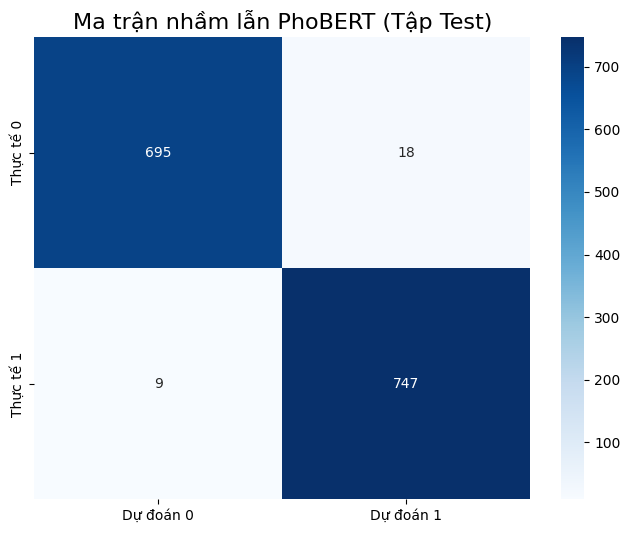

In [ ]:
if phobert_model is not None:
    # Đóng băng các lớp của PhoBERT để chỉ huấn luyện các lớp phân loại phía trên
    phobert_model.trainable = False

    # Định nghĩa kiến trúc mô hình
    input_ids = tf.keras.layers.Input(shape=(MAX_LEN,), dtype=tf.int32, name='input_ids')
    attention_mask = tf.keras.layers.Input(shape=(MAX_LEN,), dtype=tf.int32, name='attention_mask')

    # Lấy output từ PhoBERT
    # Chúng ta dùng output `pooler_output` là biểu diễn của cả câu
    phobert_output = phobert_model([input_ids, attention_mask])['pooler_output']

    # Thêm các lớp phân loại (classification head)
    x = tf.keras.layers.Dropout(0.3)(phobert_output)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    output = tf.keras.layers.Dense(1, activation='sigmoid')(x)

    # Tạo mô hình hoàn chỉnh
    model = tf.keras.Model(inputs=[input_ids, attention_mask], outputs=output)

    # Biên dịch mô hình với learning rate thấp hơn để fine-tuning
    optimizer = tf.keras.optimizers.Adam(learning_rate=3e-5)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

    model.summary()

# ==============================================================================
# --- 5. HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH ---
# ==============================================================================
if 'model' in locals():
    print("\n--- Bước 5: Huấn luyện và Đánh giá mô hình ---")

    # Chuyển đổi dữ liệu tokenized thành định dạng mà model.fit chấp nhận
    # Đó là một dict của numpy arrays
    train_inputs = {'input_ids': X_train_tokenized['input_ids'], 'attention_mask': X_train_tokenized['attention_mask']}
    test_inputs = {'input_ids': X_test_tokenized['input_ids'], 'attention_mask': X_test_tokenized['attention_mask']}

    # Callbacks
    model_path = os.path.join(OUTPUT_DIR, 'phobert_best_model.h5')
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(model_path, monitor='val_loss', save_best_only=True)
    ]

    # Huấn luyện mô hình
    # Transformers thường cần ít epochs hơn để fine-tuning
    history = model.fit(
        train_inputs, y_train,
        validation_split=0.2, # Dùng 20% tập train làm tập validation
        epochs=25,
        batch_size=16, # Batch size nhỏ hơn do mô hình lớn
        callbacks=callbacks,
        verbose=1
    )

    print(f"\n✅ Huấn luyện hoàn tất. Đang đánh giá trên tập Test...")

    # Đánh giá
    best_model = tf.keras.models.load_model(model_path, custom_objects={"TFRobertaModel": TFRobertaModel})
    loss, accuracy = best_model.evaluate(test_inputs, y_test, verbose=0)
    print(f"Độ chính xác trên tập Test: {accuracy * 100:.2f}%")

    y_pred = (best_model.predict(test_inputs) > 0.5).astype(int)

    print("\nBáo cáo phân loại (Classification Report):")
    print(classification_report(y_test, y_pred, target_names=['0: Không trầm cảm', '1: Có trầm cảm']))

    # Vẽ ma trận nhầm lẫn
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Dự đoán 0', 'Dự đoán 1'],
                yticklabels=['Thực tế 0', 'Thực tế 1'])
    plt.title('Ma trận nhầm lẫn PhoBERT (Tập Test)', fontsize=16)
    plt.show()


--- Bước 6: Vẽ đồ thị lịch sử huấn luyện ---


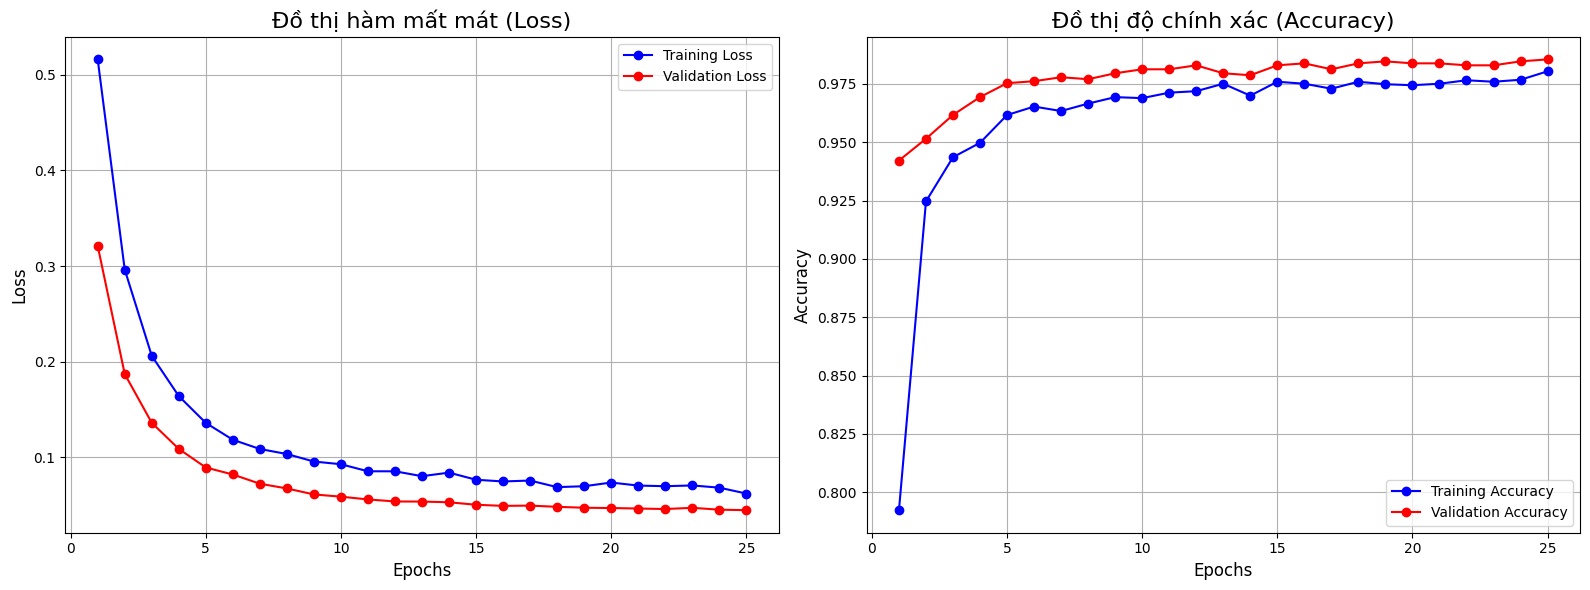

In [ ]:
# ==============================================================================
# --- 6. VẼ ĐỒ THỊ LỊCH SỬ HUẤN LUYỆN (LOSS & ACCURACY) ---
# ==============================================================================
print("\n--- Bước 6: Vẽ đồ thị lịch sử huấn luyện ---")

# Lấy dữ liệu loss và accuracy từ đối tượng history
training_loss = history.history['loss']
validation_loss = history.history['val_loss']
training_accuracy = history.history['accuracy']
validation_accuracy = history.history['val_accuracy']

# Tạo một dãy số tương ứng với số epochs đã chạy
epochs_range = range(1, len(training_loss) + 1)

# Tạo figure và axes cho 2 biểu đồ
plt.figure(figsize=(16, 6))

# --- Biểu đồ 1: Training & Validation Loss ---
plt.subplot(1, 2, 1)
plt.plot(epochs_range, training_loss, 'b-o', label='Training Loss')
plt.plot(epochs_range, validation_loss, 'r-o', label='Validation Loss')
plt.title('Đồ thị hàm mất mát (Loss)', fontsize=16)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True)

# --- Biểu đồ 2: Training & Validation Accuracy ---
plt.subplot(1, 2, 2)
plt.plot(epochs_range, training_accuracy, 'b-o', label='Training Accuracy')
plt.plot(epochs_range, validation_accuracy, 'r-o', label='Validation Accuracy')
plt.title('Đồ thị độ chính xác (Accuracy)', fontsize=16)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True)

# Điều chỉnh layout và hiển thị biểu đồ
plt.tight_layout()
plt.show()